In [2]:
import shutil
import pandas as pd
import random

import copy
import numpy as np # Import numpy for checking finite values
import matplotlib.pyplot as plt # Import matplotlib for potential debugging

import os
import math # Import math for ceil
from sklearn.manifold import TSNE # Import TSNE to check default perplexity

import os
import glob
import json
import numpy as np
import tensorflow as tf
import sys
from itertools import zip_longest
import optuna
from sklearn import metrics

In [3]:
import sys
fixed_path = 'C:\\Users\\Enrico Didoli\\0.Master_Thesis\\'
#fixed_path = 'C:\\Users\\admin\\0.Master_Thesis\\'
#fixed_path = '/content/drive/MyDrive/0.Master_Thesis/'

if fixed_path not in sys.path:
    sys.path.append(fixed_path)

old_cellcnn_path = f'{fixed_path}Final_CellCNN/Old_CellCNN/'
if old_cellcnn_path not in sys.path:
    sys.path.append(old_cellcnn_path)

cellcnn_path = f'{fixed_path}Final_CellCNN/'
if cellcnn_path not in sys.path:
    sys.path.append(cellcnn_path)

general_functions_path = f'{fixed_path}General_Functions/'
if general_functions_path not in sys.path:
    sys.path.append(general_functions_path)

save_path = f'{fixed_path}Final_CellCNN/results/'
if save_path not in sys.path:
    sys.path.append(save_path)

In [4]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid',
                'All_fixed_functions']

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)

# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

import os

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration

timepoints_elaboration rimosso dalla cache
results_elaboration non trovato nella cache
new_datasets_generation non trovato nella cache
run_models non trovato nella cache
old_cellCnn.model non trovato nella cache
old_cellCnn.utils non trovato nella cache
old_cellCnn.downsample non trovato nella cache
old_cellCnn.model_grid non trovato nella cache
All_fixed_functions non trovato nella cache


In [5]:
def remove_labels(new_test_datasets):
    new_no_label_test_datasets = []
    for dataset in new_test_datasets:
        if 'IsBlast' in dataset.columns:
            dataset = dataset.drop(columns = ['IsBlast'])

        new_no_label_test_datasets.append(dataset)
    print(len(new_no_label_test_datasets))
    return new_no_label_test_datasets

def show_blast_distribution_perc(ALL_DATASETS, return_perc = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_perc_list.append(round((blast_n/len(dataset))*100, 2))

    positions = range(1, len(tot_perc_list) + 1)

    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), [max(tot_perc_list)]*len(tot_perc_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), tot_perc_list)
    ax1.set_xticks(positions)

    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

    ax2.set_xticklabels(tot_perc_list, size = 'x-small')
    plt.show()

    if return_perc:
        return tot_perc_list

def show_blast_distribution_num(ALL_DATASETS, return_num = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_num_list.append(blast_n)

    positions = range(1, len(tot_num_list) + 1)

    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_num_list) + 1)), [max(tot_num_list)]*len(tot_num_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_num_list) + 1)), tot_num_list)
    ax1.set_xticks(positions)

    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

    ax2.set_xticklabels(tot_num_list, size = 'x-small')
    plt.show()

    if return_num:
        return tot_num_list

def grid_or_rand_model(grid):
    if grid:
        remove_from_cache(['old_cellCnn.model_grid'])
        from old_cellCnn.model_grid import CellCnn
    else:
        remove_from_cache(['old_cellCnn.model'])
        from old_cellCnn.model import CellCnn
    return CellCnn

def train_val_finalizing(train_datasets, val_datasets, grid, labels, no_val = False):
    """
    Renames rain and valdation sets.
    Removes Labels in case of grid search or no labels required.
    """
    if grid:
        if not no_val:
            val = remove_labels(val_datasets)
        train = remove_labels(train_datasets)

        print(f'Labels from Train and Validations Sets have been REMOVED.\nGrid Search Ready!')
    else:
        if not labels: # if random search but we don't want use labels
            if not no_val:
                val = remove_labels(val_datasets)
            train = remove_labels(train_datasets)

            print(f'labels from Train and Validations Sets have been REMOVED.\nRandom Search Ready!')

        else:
            if not no_val:
              val = remove_labels
            train = train_datasets
            val = val_datasets
            print(f'Labels from Train and Validations Sets have been PRESERVED.\nRandom Search Ready!')
    if not no_val:
        return train, val
    else:
        return train

def prepare_results_to_save(results_list, par_list = ['config', 'model_sorted_idx']):
    """
    Construct a list of dictionaries to store predictions
    Each dictionary contains the configuration and the sorted runs for each trial
    """
    tot_trials_res = []

    for res in results_list:
        needed_results = {}
        for key, value in res.items():
            if key in par_list:
                needed_results[key] = value

        tot_trials_res.append(needed_results)
    return tot_trials_res

def retrieve_labels(datasets_extracted, remove = False, concat = False, flat = False):

    per_donor_original_datasets = []
    per_donor_original_y = []

    for donor in datasets_extracted:
        donor_datasets = []
        donor_ys = []
        for dataset in donor:
            if (dataset['IsBlast'] == 1).sum() > 0:
                donor_ys.append(1)
            else:
                donor_ys.append(0)

            if remove:
                dataset = dataset.drop(columns = ['IsBlast'])

            donor_datasets.append(dataset)

        if concat:
            per_donor_original_datasets += donor_datasets
            per_donor_original_y += donor_ys
        else:
            per_donor_original_datasets.append(donor_datasets)
            per_donor_original_y.append(donor_ys)


    if flat:
        per_donor_original_datasets = flatten(per_donor_original_datasets)
        per_donor_original_y = flatten(per_donor_original_y)

    return per_donor_original_datasets, per_donor_original_y

def subset_sampling(dataset, ncells, nsubsets, seed):
    resampled_datasets = []
    resampled_y = []
    blast_perc = []

    for i in range(nsubsets):
        seed += 10
        #print(f'seed:{seed}')
        resampled_cells = dataset.sample(ncells, replace = True, random_state = seed).reset_index(drop=True) # sample cells

        if (resampled_cells['IsBlast'] == 1).sum() > 0: #check label
                resampled_y.append(1)
                blast_perc.append((resampled_cells[resampled_cells['IsBlast'] == 1]).sum()/len(resampled_cells))
        else:
                resampled_y .append(0)
                blast_perc.append(0)
        resampled_cells = resampled_cells.drop(columns = ['IsBlast']) #remove isblast column

        resampled_datasets.append(resampled_cells)
    return    resampled_datasets,  resampled_y , blast_perc, seed


def get_timepoints_predictions(total_pred_lists, per_donor_original_test_y, threshold):
    total_labels = []

    for patient in total_pred_lists:
        patient_timepoints_labels = []

        for timepoint in patient:
            timepoint_f1_scores = []
            blast_labelled_timepoint_scores = []

            true_y = timepoint.iloc[-1]

            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                blast_labelled_perc = sub.sum()/len(true_y)
                blast_labelled_timepoint_scores.append(blast_labelled_perc) #percentage of timepoints labelled as with blast cells

            mean_timepoint_blast_score = np.mean(blast_labelled_timepoint_scores) # mean percentage of timepoints labelled as with blast cells

            if mean_timepoint_blast_score >= threshold*0.01:
                patient_timepoints_labels.append(1)
            else:
                patient_timepoints_labels.append(0)

        total_labels.append(patient_timepoints_labels)
    return total_labels


def get_trial_pred_per_timepoint(total_pred_lists, per_donor_original_test_y):
    plot_data = []
    boxplot_data = []
    total_timepoint_prediction_per_trial = []

    for patient, patient_ys in zip(total_pred_lists, per_donor_original_test_y):
        timepoint_prediction_per_trial = []

        for timepoint, true_timepoint_y in zip(patient, patient_ys):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"

            trial_level_label_prediction = []
            true_y = timepoint.iloc[-1]
            timepoint_boxplot_data = []

            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint

                trial_perc = sub.sum()/len(true_y)
                #trial_perc = sub.sum()/min(1, true_y.sum())

                #trial_level_label_prediction.append((blast_labelled_perc >= threshold*0.01).astype(int))
                plot_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_perc
                })

                timepoint_boxplot_data.append(trial_perc)

            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })

    return plot_data, boxplot_data

def compute_timepoint_best_f1(timepoint_preds):
        """we are taking the best f1 score. because we are not tuning the model. we are just trying to predict the label of the timepoint"""
        timepoint_score = []

        resampled_true_y = timepoint_preds.iloc[-1] # get labels of resampled subsets
        #print(timepoint_preds.iloc[:-1]) #labels

        # initialize variables
        best_f1 = -1
        counter = 0

        for h in range(len(timepoint_preds) - 1):
            sub = timepoint_preds.iloc[h] # extrsct trial pediction

            f1 = f1_score(resampled_true_y, sub, pos_label = 1) # compute the f1_score
            if f1 > best_f1:
                best_f1_idx = counter
            counter += 1

        print(best_f1_idx)
        best_sub = timepoint_preds.iloc[best_f1_idx]
        #print(len(true_y))
        blast_score = best_sub.sum()
        print('')
        #print(best_sub)
        #print(f'blast_score: {blast_score}\n')
        timepoint_score = blast_score.sum()/len(resampled_true_y)
        return (timepoint_score, list(resampled_true_y))


def find_threshold(total_scores, per_donor_original_val_y):
    best_f1 = -1
    best_thr = -1
    tot_mean_f1_scores = []
    threshold_predictions = []
    for threshold in list(range(1,101)):
        f1_scores = []
        patient_predictions = []
        for patient_score, patient_y in zip(total_scores, per_donor_original_val_y):
            scores = []

            for timep in patient_score:
                # get mean columns predicted probabilities
                scores.append(timep[0])

            y_pred = []
            y_pred = (np.array(scores) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
            #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')
            #print(patient_y)
            #print(y_pred)
            timepoint_f1_score = f1_score(patient_y, y_pred, pos_label = 1, zero_division=1)
            #print(f'f1_score: {timepoint_f1_score}\n')

            f1_scores.append(timepoint_f1_score)

            patient_predictions.append(list(y_pred))

        threshold_predictions.append(patient_predictions)

        #print(f1_scores)
        mean_f1_score = np.mean(f1_scores)
        tot_mean_f1_scores.append(mean_f1_score)

        if mean_f1_score > best_f1:
                best_f1 = mean_f1_score
                best_thr = threshold*0.01
        #print('')

        #patient_f1_scores.append(timepoint_f1_score)
    #plot thresholds
    plt.plot(list(range(1,101)), tot_mean_f1_scores)
    #for th in threshold_predictions:
        #print(th)

    #find threshold
    max_mean_f1 = max(tot_mean_f1_scores)
    best_thresholds_idx = []

    best_thresholds_idx = [i for i, f1 in enumerate(tot_mean_f1_scores) if f1 == max_mean_f1]
    #print(best_thresholds_idx)

    robust_best_thr_idx = np.median(best_thresholds_idx)
    #print(np.median(list(range(5))))
    print(f'Chosen threshold: {robust_best_thr_idx}' )
    return robust_best_thr_idx


def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    nested = list(nested)
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result



def CV_train_val_splits(healthy_donors, blast_donors, mixed_donors,  test_donors_idx):
    h_pat, b_pat, m_pat = healthy_donors.copy(), blast_donors.copy(), mixed_donors.copy()

    for pat in test_donors_idx:
        if pat in healthy_donors:
            h_pat.remove(pat)
        if pat in blast_donors:
             b_pat.remove(pat)
        if pat in mixed_donors:
            m_pat.remove(pat)

    #print(h_pat, b_pat, m_pat)

    train_perm = []
    for hp in h_pat:
        for mp in m_pat:
            train_perm.append([hp, mp, b_pat[0], b_pat[1]])
            train_perm.append([hp, mp, b_pat[0], b_pat[2]])
            train_perm.append([hp, mp, b_pat[1], b_pat[2]])

    tot_train_val_perm = h_pat + b_pat + m_pat
    val_perm = []
    for element in train_perm:
        q = set(tot_train_val_perm.copy()) - set(element)
        val_perm.append(list(q))

    for t_fold, v_fold in zip(train_perm, val_perm):
        print(t_fold, v_fold)
    return train_perm, val_perm


def chosen_folds(iterations, train_perm, val_perm, seed = 42):
    print(seed)
    np.random.seed(seed)
    tot_perm = len(train_perm)

    idx = np.arange(tot_perm)
    np.random.shuffle(idx)

    chosen_folds = []
    for index in idx[:iterations]:
        chosen_folds.append([train_perm[index], val_perm[index]])

    return chosen_folds


def run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, seed_list, hyper,
                             grid = True, labels = False, trials = 1, cells_per_sub = 200, best_nsub = 200):


    train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels)
    new_test_datasets = flatten(new_test_datasets)
    test = remove_labels(new_test_datasets)
    no_label_val = remove_labels(new_val_datasets)

    models_lists = trials_train_CellCNN_old(CellCnn, train, #new_train_datasets_no_labels,
                                  new_train_y,
                                  val, #new_val_datasets_no_labels,
                                  new_val_y, test, trials = trials,
                                  n_cell = cells_per_sub, nsubset = best_nsub,
                                  max_epochs=50, nrun=15, seed_list = seed_list, hyper = hyper)

    return models_lists

def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []

    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []

    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []

        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)

            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []

            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification

            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs

            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)

            print(f'Len of Mean: {len(positive_probs_mean)}')

            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials

            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))

        mean_probs_per_patient.append(timepoints_mean_probs)

        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []

    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"

            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets

                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)

                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)

                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })


                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)

            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })

            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })

    return prob_data, boxplot_data, f1_data

def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):

    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []

    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []

    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []

        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(len(models_lists))]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1

            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)

                # predict labels
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []

                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)

                 #it converts the list of (list of) probabilities into an array of lists of prob

                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))

                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells

            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)


            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials

            per_dataset_resampled_ys.append(total_resampled_y)

        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)

        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)

    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y

def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []

    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division


def retrieve_nsub_models_names(n_sub_tuning_path):
    """ Retrieve nsub folders names """

    def extract_num(folder_name):
        if 'model_' in folder_name:
            return folder_name
    # get folder_names
    n_sub_cartelle = [
        nome for nome in os.listdir(n_sub_tuning_path)
        if os.path.isdir(os.path.join(n_sub_tuning_path , nome))]

    n_sub_models = [
        extract_num(model) for model in n_sub_cartelle
        if extract_num(model) is not None]

    return n_sub_models

def generate_seeds(n = 10, seed = None):
    """ Generate seed list """
    if seed is None:
        print('Warning: random generation. No Reproducibility!')
        print('Reproducibility -> add "seed:int()" parameter!')
    else:
        np.random.seed(seed)
    return np.random.choice(10**6, n)

def find_best_nsubs(f1_step_1, nsub_list, n = 5, indices = False):
    """ Returns the n nsub values that performed best. If multiple values have the highest f1_score, higher values are prefered"""

    idx = np.argsort(f1_step_1) # fi_step_1 elements' indices ordered in acscending order (the last element is the index of the best element in f1_step_1)
    unique_values = np.sort(list(set(f1_step_1.copy()))) #sort function returns the sorted uniques values of a list

    f1_5_best, best_5_idx = [], []
    for value in unique_values[::-1]:
        counter = len(f1_step_1) - 1

        for element in f1_step_1[::-1]:

            if element == value:
                f1_5_best.append(element)
                best_5_idx.append(counter)

            if len(best_5_idx) == n:
                print(f'5 best f1_score values: {f1_5_best} at indexes: {best_5_idx}')

                if indices:
                    return np.sort(np.array(nsub_list)[best_5_idx]), best_5_idx
                else:
                    return np.sort(np.array(nsub_list)[best_5_idx])

            counter -= 1
    return



def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []

    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []

    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []

        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)

            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []

            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification

            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs

            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)

            print(f'Len of Mean: {len(positive_probs_mean)}')

            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials

            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))

        mean_probs_per_patient.append(timepoints_mean_probs)

        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score


def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []

    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division


def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):

    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []

    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []

    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []

        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1

            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)

                # predict labels
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []

                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)

                 #it converts the list of (list of) probabilities into an array of lists of prob

                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))

                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells

            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)


            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials

            per_dataset_resampled_ys.append(total_resampled_y)

        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)

        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)

    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y





def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []

    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []

    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []

        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)

            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []

            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification

            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs

            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)

            print(f'Len of Mean: {len(positive_probs_mean)}')

            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials

            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))

        mean_probs_per_patient.append(timepoints_mean_probs)

        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

def find_robust_threshold(mean_probs_per_patient, metric = 'f1', closest = False):

    if metric == 'f1':
        metric_score = f1_score
    elif metric == 'recall':
        metric_score = recall_score
    elif metric == 'roc':
        metric_score = roc_auc_score
    elif metric == 'accuracy':
        metric_score = accuracy_score
    elif metric == 'precision':
        metric_score = precision_score

    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []

    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:

            for timep, timep_res_y in patient_probs_tuple:

                # get mean columns predicted probabilities
                probs += list(timep)

                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')

        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results
        if metric in ['f1', 'recall', 'precision']:
            total_f1_score = metric_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        else:
            total_f1_score = metric_score(resampled_ys, y_pred)
        #print(f'f1_score: {total_f1_score}\n')

        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes

        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')

    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []

    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx) + 1

    print(tot_per_tr_f1_scores)

    lowest_distance = 100
    thr_distances = []
    if closest:
        print(np.array(tot_per_tr_f1_scores)[best_thresholds_idx])
        for thr_idx in np.array(list(range(1,101)))[best_thresholds_idx]:
            thr_dist = abs(thr_idx - 50)
            if thr_dist < lowest_distance:
                thr_distances.append(thr_dist)

        min_dist_thr_idx = thr_distances.index(np.min(thr_distances))
        best_threshold = np.array(list(range(1,101)))[best_thresholds_idx][min_dist_thr_idx]

    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold - 1)]}' )

    return best_threshold, tot_per_tr_f1_scores


def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []

    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division


def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):

    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []

    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []

    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []

        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1

            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)

                # predict labels
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []

                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)

                 #it converts the list of (list of) probabilities into an array of lists of prob

                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))

                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells

            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)


            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials

            per_dataset_resampled_ys.append(total_resampled_y)

        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)

        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)

    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y

# classical CV 3 fold
def remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors,  test_donors_idx):
    h_pat, b_pat, m_pat = healthy_donors.copy(), blast_donors.copy(), mixed_donors.copy()

    # remove patients in the external test set from the three patient categories
    tot_pat = []
    for pat in test_donors_idx:
        if pat in healthy_donors:
            h_pat.remove(pat)
        if pat in blast_donors:
             b_pat.remove(pat)
        if pat in mixed_donors:
            m_pat.remove(pat)



    # generate the entire list of patients to split
    tot_pat = []
    for pat_1, pat_2, pat_3 in zip_longest(h_pat, b_pat, m_pat, fillvalue=None):
        # Only add non-None values (or whatever fillvalue you choose)
        if pat_1 is not None:
            tot_pat.append(pat_1)
        if pat_2 is not None:
            tot_pat.append(pat_2)
        if pat_3 is not None:
            tot_pat.append(pat_3)

    print(f'Remaining Patients: healthy = {h_pat}, unhealthy = {b_pat}, mixed = {m_pat}')
    print(f'All Patients in Train + Validation set: {tot_pat}')
    return h_pat, b_pat, m_pat, tot_pat

def LOOCV_division(tot_pat):
    LOOCV_folds = []
    for i, fold in enumerate(tot_pat):
        test = [fold]
        train = [sub_fold for sub_fold in tot_pat if fold != sub_fold]
        LOOCV_folds.append((train, test))
        print(train, test)
    print('')
    return LOOCV_folds

def generate_seeds(n = 10, seed = None):
    """ Generate seed list """
    if seed is None:
        print('Warning: random generation. No Reproducibility!')
        print('Reproducibility -> add "seed:int()" parameter!')
    else:
        np.random.seed(seed)
    return np.random.choice(10**6, n)



In [6]:
import sys
import numpy as np
import pandas as pd

def get_actual_size(obj):
    """Get TRUE memory size"""
    if isinstance(obj, pd.DataFrame):
        return obj.memory_usage(deep=True).sum()
    elif isinstance(obj, pd.Series):
        return obj.memory_usage(deep=True)
    elif isinstance(obj, np.ndarray):
        return obj.nbytes
    elif isinstance(obj, (list, tuple, set, dict)):
        # For containers, sum up contents
        return sys.getsizeof(obj) + sum(sys.getsizeof(item) for item in obj)
    else:
        return sys.getsizeof(obj)

def print_var_memory(var_to_check = None):
    # Display all variables with ACTUAL sizes
    all_vars = %who_ls
    sizes = []
    if var_to_check is None:
        var_to_check = all_vars


    for var_name in all_vars:
        #try:
            var = eval(var_name)

            #if var_name in  ('train_datasets_extracted','val_datasets_extracted','test_datasets_extracted'):
            if var_name in var_to_check:
                #print(var)
                if isinstance(var, (list, tuple)):
                    var = flatten(var)
                    tot = 0
                    for element in var:
                        tot += get_actual_size(element)
                    size = tot
                    sizes.append((var_name, type(var).__name__, size))
            else:
                size = get_actual_size(var)
                sizes.append((var_name, type(var).__name__, size))

        #except:
        #    pass

    # Sort by size
    sizes.sort(key=lambda x: x[2], reverse=True)

    # Pretty print
    print(f"{'Variable':<25} {'Type':<20} {'Memory':>15}")
    print("-" * 65)
    total = 0
    var_to_check = []
    for name, type_name, size in sizes:
        total += size
        if size > 1024**3:  # GB
            print(f"{name:<25} {type_name:<20} {size/(1024**3):>12.2f} GB")
            var_to_check.append(name)

        elif size > 1024**2:  # MB
            print(f"{name:<25} {type_name:<20} {size/(1024**2):>12.2f} MB")
            var_to_check.append(name)
        '''
        elif size > 1024:  # KB
            print(f"{name:<25} {type_name:<20} {size/1024:>12.2f} KB")

        else:
            print(f"{name:<25} {type_name:<20} {size:>12} bytes")
        '''
    print("-" * 65)
    print(f"{'TOTAL':<25} {'':<20} {total/(1024**3):>12.2f} GB")
    return var_to_check

print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
-----------------------------------------------------------------
TOTAL                                                  0.00 GB


[]

In [41]:

def strat_CV(h_pat, b_pat, m_pat, shuffle = False, seed = None):
    """ Custom stratified CV. Builded to work with heatlhy, unhealthy and mixed patients"""

    print(h_pat, b_pat, m_pat)
    if shuffle:
        if seed:
            np.random.seed(seed)
        np.random.shuffle(h_pat)
        np.random.shuffle(b_pat)
        np.random.shuffle(m_pat)
        print(h_pat, b_pat, m_pat)

    # divide patients
    patients_division = []
    for h, b, m in zip_longest(h_pat, b_pat, m_pat):
        f = [h, b, m]
        while None in f:
            f.remove(None)
        patients_division.append(f)

    # build folds
    folds = []
    counter = 0
    for _ in patients_division:
        val = patients_division[counter]
        train = patients_division.copy()
        train.remove(val)
        folds.append([flatten(train), val])
        counter += 1
    return folds


from itertools import zip_longest
def classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 3, LOOCV_test = None, shuffle_seed = None):
    # if present, remove the test patient from h,b,m sets
    #print(f'LOOCV_test: {LOOCV_test}')
    if LOOCV_test is not None:
        if str(LOOCV_test) in h_pat: #healthy
            h_pat = [pat for pat in h_pat if pat != str(LOOCV_test)]
        elif str(LOOCV_test) in b_pat: #unhealthy
            b_pat = [pat for pat in b_pat if pat != str(LOOCV_test)]
        elif str(LOOCV_test) in m_pat: #mixed
            m_pat = [pat for pat in m_pat if pat != str(LOOCV_test)]

        tot_pat = []
        for pat_1, pat_2, pat_3 in zip_longest(h_pat, b_pat, m_pat, fillvalue=None):
            # Only add non-None values (or whatever fillvalue you choose)
            if pat_1 is not None:
                tot_pat.append(pat_1)
            if pat_2 is not None:
                tot_pat.append(pat_2)
            if pat_3 is not None:
                tot_pat.append(pat_3)

    sub_len = int(len(tot_pat)/folds) # len of each fold
    print(f'Minimum number of patients in each fold: {sub_len}')

    if shuffle_seed is not None:
        np.random.seed(shuffle_seed)
        np.random.shuffle(tot_pat)
    # store the three different patietns' folds
    single_folds = []
    counter = 0
    len_counter = 0
    for fold in range(folds - 1):
        len_counter += len(tot_pat)/folds
        diff =  int(len_counter - counter)
        single_folds.append(tot_pat[counter: counter + diff])
        counter += diff
    single_folds.append(tot_pat[counter:])
    print(f'Folds: {single_folds}')

    # finally make the n train-validation combinations
    tot_folds = []
    for n_fold in range(folds):
        val_fold = single_folds[n_fold - 1]
        train_fold = []
        for fold in single_folds:
            if fold != val_fold:
                train_fold += fold

        print(f'Combination {n_fold + 1}: {train_fold, val_fold}')
        tot_folds.append([train_fold, val_fold])
    return tot_folds

def extract_fold_features(chosen_perm):
        # retireve files' id from fold patient division
    fold_features = {}
    for i, (train_set, val_set) in enumerate(chosen_perm):

        ##### Train #####
        # extract files from patients' id
        set_train_files, set_val_files = [], []
        for train_pat in train_set:
            train_files = multiple_donations[train_pat]
            set_train_files += train_files # indexes of files in ALL_DATASETS list


        train_file_perc = list(np.array(tot_perc_list)[set_train_files]) # extracts only the interested file pecentages
        train_features = [train_set, train_file_perc, np.mean(train_file_perc), np.std(train_file_perc)] # structure

        ##### Validation #####
        for val_pat in val_set:
            val_files = multiple_donations[val_pat]
            set_val_files += val_files

        val_file_perc = list(np.array(tot_perc_list)[set_val_files])
        val_features = [val_set, val_file_perc, np.mean(val_file_perc), np.std(val_file_perc)]

        # assignes train and validation features to the i-th fold combination
        fold_features[i] = [train_features, val_features]
    return fold_features


In [8]:
def run_training(CellCnn, new_train_datasets, new_train_y, new_val_datasets,
                     new_val_y, new_test_datasets, seed_list, hyper,
                                 grid = True, labels = False, trials = 1, cells_per_sub = 200, best_nsub = 200,
                                 max_epochs = 100, nrun = 15, generate = False, no_val = False):

        if no_val:
            train = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels, no_val)
        else:
            train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels, no_val)


        new_test_datasets = flatten(new_test_datasets)
        test = remove_labels(new_test_datasets)
        #no_label_val = remove_labels(new_val_datasets)

        if no_val and not generate:
            models_lists = trials_train_CellCNN_old(CellCnn, train,
                                          new_train_y, test,
                                          trials = trials,
                                          n_cell = cells_per_sub, nsubset = best_nsub,
                                          max_epochs= max_epochs, ### 100,
                                          nrun= 15, ### 15,
                                          seed_list = seed_list, hyper = hyper,
                                          #val_datasets = val, val_y = new_val_y,
                                                    generate = generate)
        elif generate:
            models_lists = trials_train_CellCNN_old(CellCnn, train,
                                          new_train_y, test,
                                          trials = trials,
                                          n_cell = cells_per_sub, nsubset = best_nsub,
                                          max_epochs= max_epochs, ### 100,
                                          nrun= 15, ### 15,
                                          seed_list = seed_list, hyper = hyper,
                                          #val_datasets = val, val_y = new_val_y,
                                                    generate = generate)
        else:
            models_lists = trials_train_CellCNN_old(CellCnn, train, new_train_y,
                                              val_datasets = val, val_y = new_val_y,
                                              test_datasets_no_labels = test,
                                              trials = trials,
                                              n_cell = cells_per_sub, nsubset = best_nsub,
                                              max_epochs= max_epochs, ### 100,
                                              nrun= 15, ### 15,
                                              seed_list = seed_list, hyper = hyper,
                                              generate = generate)


        return models_lists

In [9]:


def save_models(model, save_dir):
        import pickle
        import os

        metadata_to_save = model.all_params
        # 3. Salva i metadati in un file pickle
        with open(os.path.join(save_dir, 'metadata.pkl'), 'wb') as f:
            pickle.dump(metadata_to_save, f)
            print(f"✅ Metadata salvati in {save_dir}/metadata.pkl")




# code

In [10]:
import time
import pickle
#check_time_spent_start = time.time()

import os
import csv
import pandas as pd

exp = 1 ###
starting_seed =  42
n_sub = 3                                  #int(config_df.loc[0, 'n_sub'])
n_cells = 100000
blast_perc = [0.0001, 0.001, 0.01]         #config_df.loc[0, 'blast_perc']
nfilter = [5, 7, 9]
maxpool_p = [0.01, 1, 10, 100]
learning_r = [0.001, 0.005]
grid = False
labels = False
hyper = (nfilter, maxpool_p, learning_r)

print(starting_seed)
print(n_sub)
print(n_cells)
print(blast_perc)
print(nfilter)
print(maxpool_p)
print(learning_r)
print(grid)
print(labels)

config = {}
config['starting_seed'] = starting_seed
config['n_sub '] = n_sub
config['n_cells'] = n_cells
config['blast_perc'] = blast_perc
config['nfilter'] = nfilter
config['maxpool_p'] = maxpool_p
config['learning_r'] = learning_r
config['grid'] = grid
config['labels'] = labels




42
3
100000
[0.0001, 0.001, 0.01]
[5, 7, 9]
[0.01, 1, 10, 100]
[0.001, 0.005]
False
False


In [11]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid',
                'All_fixed_functions']

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)


# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration


timepoints_elaboration rimosso dalla cache
results_elaboration rimosso dalla cache
new_datasets_generation rimosso dalla cache
run_models rimosso dalla cache
old_cellCnn.model rimosso dalla cache
old_cellCnn.utils rimosso dalla cache
old_cellCnn.downsample rimosso dalla cache
old_cellCnn.model_grid non trovato nella cache
All_fixed_functions non trovato nella cache


In [12]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)#, remove_control = True)



Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE1_D15_2.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE1_D78.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE2_D15_2.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.

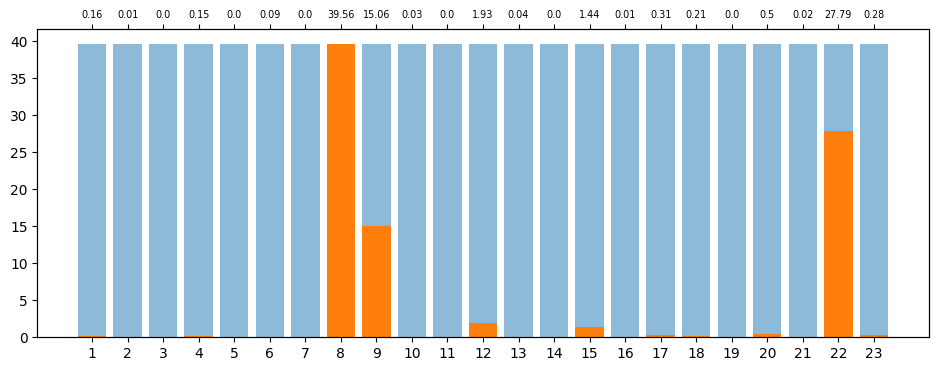

[0.16, 0.01, 0.0, 0.15, 0.0, 0.09, 0.0, 39.56, 15.06, 0.03, 0.0, 1.93, 0.04, 0.0, 1.44, 0.01, 0.31, 0.21, 0.0, 0.5, 0.02, 27.79, 0.28]


In [13]:

tot_perc_list = show_blast_distribution_perc(ALL_DATASETS, return_perc = True)
print(tot_perc_list)

In [14]:
print(multiple_donations)
print(multiple_donations.keys())


{'11': [0, 1, 2], '12': [3, 4], '1': [5, 6], '2': [7, 8], '3': [9, 10], '4': [11, 12, 13], '6': [14, 15], '7': [16, 17, 18], '8': [19, 20], '9': [21, 22]}
dict_keys(['11', '12', '1', '2', '3', '4', '6', '7', '8', '9'])


In [61]:
full_LOPOCV_dict = []
for patient in multiple_donations.keys():
    prov_multiple = multiple_donations.copy()
    prov_multiple.pop(patient) # remove patient

    test = {} #store patient
    test[patient] = multiple_donations[patient]

    full_LOPOCV_dict.append((prov_multiple, test)) #append folds
    print(prov_multiple.keys(), test.keys())

dict_keys(['12', '1', '2', '3', '4', '6', '7', '8', '9']) dict_keys(['11'])
dict_keys(['11', '1', '2', '3', '4', '6', '7', '8', '9']) dict_keys(['12'])
dict_keys(['11', '12', '2', '3', '4', '6', '7', '8', '9']) dict_keys(['1'])
dict_keys(['11', '12', '1', '3', '4', '6', '7', '8', '9']) dict_keys(['2'])
dict_keys(['11', '12', '1', '2', '4', '6', '7', '8', '9']) dict_keys(['3'])
dict_keys(['11', '12', '1', '2', '3', '6', '7', '8', '9']) dict_keys(['4'])
dict_keys(['11', '12', '1', '2', '3', '4', '7', '8', '9']) dict_keys(['6'])
dict_keys(['11', '12', '1', '2', '3', '4', '6', '8', '9']) dict_keys(['7'])
dict_keys(['11', '12', '1', '2', '3', '4', '6', '7', '9']) dict_keys(['8'])
dict_keys(['11', '12', '1', '2', '3', '4', '6', '7', '8']) dict_keys(['9'])


In [16]:
LOPOCV_patients_folds = []
for train_set_dict, val_set_dict in full_LOPOCV_dict:

    healthy_donors, blast_donors, mixed_donors = donor_division(train_set_dict, ALL_DATASETS)

    left_out_patient = list(val_set_dict.keys())
    # defined the External validation set, remove the patients from the categories
    h_pat, b_pat, m_pat, tot_pat = remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors, left_out_patient)

    # remove the Left Out patient and generate the folds for the 5 folds CV
    k_folds = classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 5, LOOCV_test = left_out_patient[0])

    # k_folds is for the tuning. left_out_patient for the final training
    LOPOCV_patients_folds.append((k_folds, left_out_patient))

{'12': [1, 1], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1]}
Remaining Patients: healthy = [], unhealthy = ['12', '2', '6', '8', '9'], mixed = ['1', '3', '4', '7']
All Patients in Train + Validation set: ['12', '1', '2', '3', '6', '4', '8', '7', '9']
Minimum number of patients in each fold: 1
Folds: [['12'], ['1', '2'], ['3', '6'], ['4', '8'], ['7', '9']]
Combination 1: (['12', '1', '2', '3', '6', '4', '8'], ['7', '9'])
Combination 2: (['1', '2', '3', '6', '4', '8', '7', '9'], ['12'])
Combination 3: (['12', '3', '6', '4', '8', '7', '9'], ['1', '2'])
Combination 4: (['12', '1', '2', '4', '8', '7', '9'], ['3', '6'])
Combination 5: (['12', '1', '2', '3', '6', '7', '9'], ['4', '8'])
{'11': [1, 1, 0], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1]}
Remaining Patients: healthy = [], unhealthy = ['2', '6', '8', '9'], mixed = ['11', '1', '3', '4', '7']
All Patients in T

# prepare stratified CV and  parameter tuning + classical kfold cv

In [17]:
# all possible combinations of parameters
def nsub_ncells_comb(ncells_list, nsub_list):
    all_nsub_ncells_comb = []
    for ncells_value in ncells_list:
        for nsub_value in nsub_list:
            all_nsub_ncells_comb.append([ncells_value, nsub_value])
    return all_nsub_ncells_comb



blocks = 14
nsub_step = 50
max_ncells = 700
ncells_step = 100

config['blocks'] = blocks
config['nsub_step'] = nsub_step
config['max_ncells'] = max_ncells
config['ncells_step'] = ncells_step

# Save initial config
config_save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/folds_results/experiment_{exp}/'
os.makedirs(config_save_dir, exist_ok=True)

with open(os.path.join(config_save_dir, 'config.pkl'), 'wb') as f:
            pickle.dump(config, f)

ncells_list = list(range(ncells_step, max_ncells + ncells_step, ncells_step))
nsub_list = list(range(nsub_step, blocks*nsub_step + nsub_step, nsub_step))
print(ncells_list)
print(nsub_list)

# define all possible combinations of parameters
all_nsub_ncells_comb = nsub_ncells_comb(ncells_list, nsub_list)

[100, 200, 300, 400, 500, 600, 700]
[50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700]


# Pre build of Artificial sample to avoid reload files

In [18]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
ALL_DATASETS              list                         1.52 GB
-----------------------------------------------------------------
TOTAL                                                  1.52 GB


['ALL_DATASETS']

# ncells and nsub bayesian tuning

In [19]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid',
                'All_fixed_functions']

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)


# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration


timepoints_elaboration rimosso dalla cache
results_elaboration rimosso dalla cache
new_datasets_generation rimosso dalla cache
run_models rimosso dalla cache
old_cellCnn.model rimosso dalla cache
old_cellCnn.utils rimosso dalla cache
old_cellCnn.downsample rimosso dalla cache
old_cellCnn.model_grid non trovato nella cache
All_fixed_functions non trovato nella cache


In [20]:
%%time
import optuna
import time
import numpy as np
from optuna.samplers import TPESampler # Added this line

exp = 1
counter_resampling_seed = 0 ###


for LOPOCV_fold_idx, (train_kfolds, test_pat) in enumerate(LOPOCV_patients_folds): # for each LOPO fold

    #############
    ## generate the artificial sample to avoid the generation at each proposed combination
    #############

    # load the samples once
    if LOPOCV_fold_idx != 0:
        multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

    print(f'Test patient: {test_pat}')

    # pre-generation of augmented datasets
    fold_features = extract_fold_features(train_kfolds) #Fold feature dictionaty creation

    # generate the Artificial Samples
    artificial_samples_folds = []
    for fold, (train_features, val_features) in fold_features.items():
        train_donors_idx, val_donors_idx = train_features[0], val_features[0] # retrieve patients form fold features dictionary

        # extraxt samples using pre-slitted indexes
        train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
        val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
        test_datasets_extracted = donation_extraction(test_pat, multiple_donations, ALL_DATASETS)

        # generate Artificial Samples
        (new_train_datasets, new_train_y,
         new_val_datasets,   new_val_y, _, _ ) = splitting_and_dataset_elaboration(train_datasets_extracted,
                                                                            val_datasets_extracted,
                                                                            test_datasets_extracted,
                                                                            n_sub, n_cells,           # number of AS, number of cells per AS
                                                                            starting_seed + LOPOCV_fold_idx, # seed for random extraction
                                                                            blast_perc = blast_perc,  # % of blast cells extracted
                                                                            per_perc = True)          # one Unhealthy AS per %

        # store generated AS
        artificial_samples_folds.append([new_train_datasets, new_train_y, new_val_datasets, new_val_y])#, new_test_datasets, new_test_y])

    # delete for RAM saving
    del ALL_DATASETS
    del test_datasets_extracted
    del train_datasets_extracted
    del new_train_datasets
    del val_datasets_extracted
    del new_val_datasets

    print(f'End of Artificial Sample generation')


    for i in range(1):
        print(f'Start Bayesian Search for optimal ncells and nsubs parameters')

        #baywsian search and ncells and nsub tuning
        #resampling_seeds = generate_seeds(len(k_folds)*2, seed = starting_seed + fold_idx)
        #print(resampling_seeds)

        # prepare storing variables

        tested_par = []        #save parameter explored
        best_thresholds = []
        roc_metrics = []

        actual_epochs_list = []
        ##### Run ncells tuning #####
        # 1. Create the study outside the loop
        # direction="maximize"because we want to maximize the f1-score
        sampler = TPESampler(seed=starting_seed + LOPOCV_fold_idx)
        study = optuna.create_study(direction="maximize", sampler = sampler)

        # define combinations of parameters
        all_nsub_ncells_comb = nsub_ncells_comb(ncells_list, nsub_list)

        print(f"Start Bayesian optimization on {len(all_nsub_ncells_comb)} possible combinations...")
        val_predicted_for_roc = []

        bayesian_comb = 10 ### 20   # number of combination to explore
        for i in range(bayesian_comb):

            # Ask parameters
            trial = study.ask()

            # decide index of the new combination to explore
            comb_index = trial.suggest_int("combo_idx", 0, len(all_nsub_ncells_comb) - 1)

            ncells, nsubs = all_nsub_ncells_comb[comb_index] # retrieve ncells and nsubs
            tested_par.append((ncells, nsubs))
            #ncells, nsubs = 100, 100 ###
            ncell_start = time.time()
            print(f'Model {i+1}. Testing params -> ncells: {ncells}, nsubs: {nsubs}')

            print(f'5 Fold CV started')
            tuning_predictions_folds = []
            tuning_results_folds = []
            val_predicted_for_roc_folds = []
            f1_across_folds = []
            for fold_idx, (train_features, val_features) in fold_features.items():

                print(f'\nFold: {fold_idx}\n')
                fold_start = time.time()

                # retrieve generated AS from pre-generated AS
                (new_train_datasets, new_train_y,
                 new_val_datasets, new_val_y) = artificial_samples_folds[fold_idx]

                trials = 1 ### 3  number of time the model have to be trained (at each time a different seed is used)


                seed_list = generate_seeds(len(LOPOCV_patients_folds)*2, seed = int(starting_seed/5) + len(LOPOCV_patients_folds) + fold_idx)
                tuning_prediction_seed_list = generate_seeds(trials, seed = int(starting_seed/2) + trials + fold_idx)
                print(seed_list)
                print(tuning_prediction_seed_list)
                ##### Prepare Parameters and storage variables #####
                # grid is set to False -> Random search
                CellCnn = grid_or_rand_model(grid) #select the correct model

                # remove labels (random search without labels is required)
                train, val = train_val_finalizing(new_train_datasets, new_val_datasets, grid, labels)


                max_acc = 0
                max_f1 = 0
                tuning_predictions = []
                tuning_results = []

                try: # to ensure no errors

                        # Train Step
                        models_lists = trials_train_CellCNN_old(
                            CellCnn, train, new_train_y,
                                    val_datasets = val, val_y = new_val_y,
                                    test_datasets_no_labels = None, trials=trials,
                                    n_cell = ncells,    # Explored parameter
                                    nsubset = nsubs,     # Explored parameter
                                    max_epochs = 75,     ### 35
                                    nrun = 10,           ### 10
                                    seed_list = seed_list, hyper=hyper
                                    )

                        for model in models_lists:
                            actual_epochs_list += model.results['epochs_num']

                        #WE MUST PREDICT THE ORIGINAL SAMPLE, NOT THE ARTIFICAL ONE
                        original_val_datasets, original_val_y = retrieve_labels(val_datasets_extracted, remove = True, flat = True)
                        # Predicts
                        predictions_list, results_list = trials_test_CellCNN_old(models_lists, original_val_datasets, tuning_prediction_seed_list)

                        # Elaborate results
                        (pred_phenotype_df, accuracy_list,
                         f1_scores_list, recall_score_list) = elaborate_predictions(
                                                                        predictions_list, original_val_y,
                                                                         results=True) # show results
                        f1_across_folds.append(np.mean(f1_scores_list))
                        tuning_predictions.append(predictions_list)
                        tuning_results.append(results_list)

                        val_predicted_for_roc_folds.append((predictions_list, original_val_y)) # store full prediction

                except Exception as e:
                        print(f"Training error: {e}")


                fold_end = time.time()
                print(f'Fold: {fold_idx}: Time spent for the {(ncells, nsubs)} combination: {(fold_end- fold_start)}')


            #elaborate data from the cv (one per param comb tested)

            # threshold "tuning": at each combination of ncells, nsub, the Roc curve is computed
            predictions_list, new_val_y = [], []
            for bay_fold_idx, (pred_list, val_y) in enumerate(val_predicted_for_roc_folds):
                new_val_y += val_y                   # recreate the full list of labels
                for art_s in pred_list[0]:
                    predictions_list += [art_s[1]]   # store only the prob ob bieng classified as Positive

            fpr, tpr, thresholds = metrics.roc_curve(new_val_y, predictions_list, pos_label=1)# , zero_division = 0) # compute ROC curve

            optimal_idx = np.argmax(tpr >= np.max(tpr))  # index of the threshold that has the highest tpr
            best_thresh_mrd = thresholds[optimal_idx]    # extract the threshold

            print(f"Best Threshold for MRD (Recall=100%): {best_thresh_mrd}")

            roc_metrics.append((fpr, tpr, thresholds))   # save all the roc curve to show the results
            best_thresholds.append(best_thresh_mrd)      # save the best threshold

            val_predicted_for_roc.append(val_predicted_for_roc_folds)
            tuning_predictions_folds.append(tuning_predictions)
            tuning_results_folds.append(tuning_results)

            ################################################################################################
            # Tell to Bayesian search the results. Mandatoy to recompute the probability distrbutions
            study.tell(trial, np.mean(f1_across_folds))

            print(f'Mean F1 Score across folds: {f1_across_folds}')
            print(f'Time Spent for this trial: {time.time() - ncell_start}')


        # Risultato finale
        print("Migliori parametri trovati:")
        print(study.best_params)


    best_ncells, best_nsub = all_nsub_ncells_comb[study.best_params['combo_idx']]
    tuned_epochs = int(np.mean(actual_epochs_list)+1)

    # save results
    tuning_save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/tuning'
    os.makedirs(tuning_save_dir, exist_ok=True)

#    with open(os.path.join(tuning_save_dir, 'bayesian_mean_f1.pkl'), 'wb') as f:
#                pickle.dump(bayesian_mean_f1, f)
    with open(os.path.join(tuning_save_dir, 'tuning_results_folds.pkl'), 'wb') as f:
                pickle.dump(tuning_results_folds, f)
    with open(os.path.join(tuning_save_dir, 'tuning_predictions_folds.pkl'), 'wb') as f:
                pickle.dump(tuning_predictions_folds, f)
    with open(os.path.join(tuning_save_dir, 'best_ncells.pkl'), 'wb') as f:
                pickle.dump(best_ncells, f)
    with open(os.path.join(tuning_save_dir, 'best_nsub.pkl'), 'wb') as f:
                pickle.dump(best_nsub, f)
    with open(os.path.join(tuning_save_dir, 'tested_par.pkl'), 'wb') as f:
                pickle.dump(tested_par, f)
    with open(os.path.join(tuning_save_dir, 'best_thresholds.pkl'), 'wb') as f:
            pickle.dump(best_thresholds, f)
    with open(os.path.join(tuning_save_dir, 'roc_metrics.pkl'), 'wb') as f:
            pickle.dump(roc_metrics, f) # tpr, fpr, thresholds
    with open(os.path.join(tuning_save_dir, 'val_predicted_for_roc.pkl'), 'wb') as f:
            pickle.dump(val_predicted_for_roc, f) # prediction used to tune the threshold
    with open(os.path.join(tuning_save_dir, 'tuned_epochs.pkl'), 'wb') as f:
            pickle.dump(tuned_epochs, f) # prediction used to tune the threshold

    print(f'Before Breaking: fold idx = {LOPOCV_fold_idx}')
    if LOPOCV_fold_idx == 0:
        break
    print(f'After Breaking: fold idx = {LOPOCV_fold_idx}')


Test patient: ['11']
New training datasets creation...
7
2

New Donor
2
Tot blast data in the donor timepoints: 639
Tot blast data in the donor timepoints: 654
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 757
Tot blast data in the donor timepoints: 757
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 308059
Tot blast data in the donor timepoints: 1138160
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [  10.  100. 1000.]
Chosen # of blast cells: [  10.  100. 1000.]

New Donor
2
Tot blast data in the donor timepoints: 72
Tot blast data in the donor timepoints: 72
Extraction Done
Condition: 1
3
0
1
[0.0001, 0.001, 0.01]
3
Chosen # of blast cells: [

[I 2026-01-21 01:04:11,895] A new study created in memory with name: no-name-4b77585c-4e3a-4a03-9818-fb9fab8a4cf9


End of Artificial Sample generation
Start Bayesian Search for optimal ncells and nsubs parameters
Start Bayesian optimization on 98 possible combinations...
Model 1. Testing params -> ncells: 500, nsubs: 50
5 Fold CV started

Fold: 0

[978218 356627 353400  35653 788158 704433 857262 739570 782914 493832
 585368 137954 369553 574085 440149 212079 569022  88298 986762  36852]
[895861]
old_cellCnn.model rimosso dalla cache
12
42
labels from Train and Validations Sets have been REMOVED.
Random Search Ready!
Trial 1 started
Seed used: 978218
Seed used: 978218: <class 'numpy.int32'>
Model defined...
Fitting started...
1
No labels detected. Labels set to False
[1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1
 1 1 0 0 0]
11
11
2

# ============================================= #
Run: 0

Seed: 978218
3

 filters: 5


 filters: 5

Epoch 1/75
11/11 [==============================] - 6s 62ms/step - loss: 0.6941 - f1_score: 0.4089 - val_loss: 0.6928 - val_f1_score: 0.3333

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1
Prediction started...
seed: 895861. Type: <class 'numpy.int32'>
seed: 895861. Type: <class 'int'>

 filters: 7



C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (189 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1
Prediction started...
seed: 316213. Type: <class 'numpy.int32'>
seed: 316213. Type: <class 'int'>

 filters: 7



C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 111ms/step

 filters: 7

1/1 [==============================] - 0s 105ms/step

 filters: 5

1/1 [==============================] - 0s 94ms/step
Done
[[0.35400695 0.64599306]
 [0.24470844 0.75529152]
 [0.05901599 0.94098403]
 [0.56630808 0.43369194]
 [0.54260778 0.45739219]
 [0.5388276  0.46117238]
 [0.21852161 0.78147841]
 [0.12054128 0.87945871]
 [0.0117575  0.98824251]
 [0.20797715 0.79202283]
 [0.24093954 0.75906046]
 [0.25776346 0.74223653]]
Trial 1 Done!

Trial 0 Accuracy: 0.75
Trial 0 F1_score: 0.8
Trial 0 F1_score: 1.0
             0   1   2   3   4   5   6   7   8   9   10  11
0             1   1   1   0   0   0   1   1   1   1   1   1
True Labels   1   1   1   0   0   0   1   1   1   0   0   0
mean_accuracy over the ten trials: 0.75
accuracy_std over the ten trials: 0.0
mean_f1 over the ten trials: 0.8
std_f1 over the ten trials: 0.0
mean_recall over the ten trials: 1.0
std_recall over the ten trials: 0.0
Time spent for the (700, 450) 

In [26]:
print(tuned_epochs)

39


Python version: 3.9.23 (main, Jun  5 2025, 13:25:08) [MSC v.1929 64 bit (AMD64)]
TensorFlow version: 2.13.1
GPU Available: []


2
700 550
[0.5085853139559428, 0.5343761543432871, 0.5390668511390686, 0.46435055136680603, 0.4639928738276164, 0.5343761543432871, 0.46197667717933655, 0.40130404631296795, 0.45524200797080994, 0.49071112275123596]


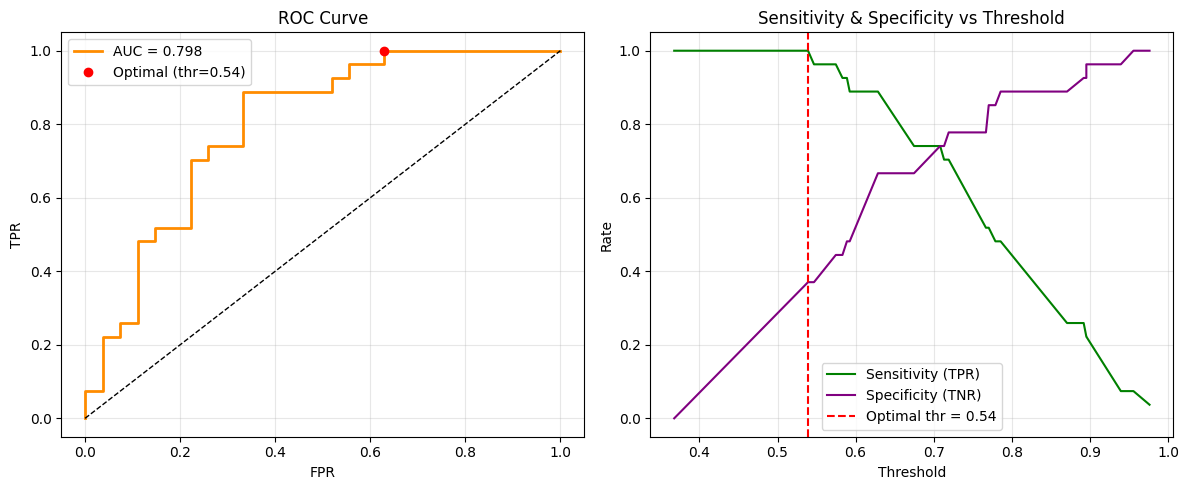

(ncells, nsubs): (500, 50), f1  scores: 0.76
(ncells, nsubs): (500, 50), rec scores: 1.0

(ncells, nsubs): (500, 550), f1  scores: 0.76
(ncells, nsubs): (500, 550), rec scores: 1.0

(ncells, nsubs): (700, 550), f1  scores: 0.7766666666666666
(ncells, nsubs): (700, 550), rec scores: 1.0

(ncells, nsubs): (100, 200), f1  scores: 0.6128205128205128
(ncells, nsubs): (100, 200), rec scores: 0.6333333333333333

(ncells, nsubs): (600, 600), f1  scores: 0.7695238095238095
(ncells, nsubs): (600, 600), rec scores: 0.9666666666666668

(ncells, nsubs): (500, 550), f1  scores: 0.76
(ncells, nsubs): (500, 550), rec scores: 1.0

(ncells, nsubs): (100, 600), f1  scores: 0.623076923076923
(ncells, nsubs): (100, 600), rec scores: 0.6

(ncells, nsubs): (400, 450), f1  scores: 0.7452813852813852
(ncells, nsubs): (400, 450), rec scores: 0.8

(ncells, nsubs): (100, 500), f1  scores: 0.623076923076923
(ncells, nsubs): (100, 500), rec scores: 0.6

(ncells, nsubs): (700, 450), f1  scores: 0.7695238095238095
(n

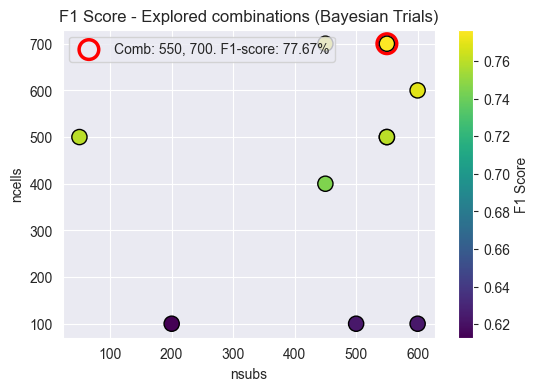

In [23]:
import os
import pickle
#for LOPOCV_fold_idx, (train_kfolds, test_pat) in enumerate(LOPOCV_patients_folds): # for each LOPO fold
for i in range(1):
    exp = 1
    LOPOCV_fold_idx = 0
    tuning_load_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/tuning'
    os.makedirs(tuning_load_dir, exist_ok=True)

    with open(os.path.join(tuning_load_dir, 'tuning_results_folds.pkl'), 'rb') as f:
                    tuning_results_folds = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'tuned_epochs.pkl'), 'rb') as f:
                    tuned_epochs = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'tuning_predictions_folds.pkl'), 'rb') as f:
                    tuning_predictions_folds = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'best_ncells.pkl'), 'rb') as f:
                    best_ncells = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'best_nsub.pkl'), 'rb') as f:
                    best_nsub = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'tested_par.pkl'), 'rb') as f:
                    tested_par = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'best_thresholds.pkl'), 'rb') as f:
                    best_thresholds = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'roc_metrics.pkl'), 'rb') as f:
                    roc_metrics = pickle.load(f)

    with open(os.path.join(tuning_load_dir, 'val_predicted_for_roc.pkl'), 'rb') as f:
                    val_predicted_for_roc = pickle.load(f)

    #################################################################

    best_idx = tested_par.index((best_ncells, best_nsub))
    print(best_idx)

    print(best_ncells, best_nsub)
    print(best_thresholds)

    val_predicted_for_roc_folds = val_predicted_for_roc[best_idx]

    predictions_list, new_val_y = [], []
    for pred_list, val_y in val_predicted_for_roc_folds:
        new_val_y += val_y

        for art_s in pred_list[0]:
            predictions_list += [art_s[1]]

    #################################################################

    import matplotlib.pyplot as plt
    from sklearn import metrics
    fpr, tpr, thresholds = metrics.roc_curve(new_val_y, predictions_list, pos_label=1)

    opt_idx = np.argmax(tpr >= 1.0)
    #J = tpr - fpr
    #opt_idx = np.argmax(J)

    opt_threshold = thresholds[opt_idx]
    opt_fpr, opt_tpr = fpr[opt_idx], tpr[opt_idx]

    fpr, tpr, thresholds = metrics.roc_curve(new_val_y, predictions_list, pos_label=1)
    roc_auc = metrics.auc(fpr, tpr)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    # ROC Curve
    axs[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
    axs[0].plot(opt_fpr, opt_tpr, 'ro', label=f'Optimal (thr={opt_threshold:.2f})')
    axs[0].plot([0,1], [0,1], 'k--', lw=1)
    axs[0].set_xlabel('FPR')
    axs[0].set_ylabel('TPR')
    axs[0].set_title('ROC Curve')
    axs[0].legend()
    axs[0].grid(alpha=0.3)

    # Threshold plot
    axs[1].plot(thresholds, tpr, label='Sensitivity (TPR)', color='green')
    axs[1].plot(thresholds, 1 - fpr, label='Specificity (TNR)', color='purple')
    axs[1].axvline(opt_threshold, color='red', linestyle='--', label=f'Optimal thr = {opt_threshold:.2f}')
    axs[1].set_xlabel('Threshold')
    axs[1].set_ylabel('Rate')
    axs[1].set_title('Sensitivity & Specificity vs Threshold')
    axs[1].legend()
    axs[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    #################################################################

    ncells_to_plot = []
    nsubs_to_plot = []
    f1_score_to_plot = []
    recall_score_to_plot = []

    tested_ncells, tested_nsubs = [], []
    heatmap_dict = {}
    for (ncells, nsubs), fold in zip(tested_par, val_predicted_for_roc):
        f1_fold, rec_fold = [], []
        for pred_list, val_y in fold:
            pred_phenotype_df, accuracy_list, f1_score_list, recall_score_list = elaborate_predictions(
                                    pred_list, val_y, results=False
                                )
            f1_fold.append(f1_score_list)
            rec_fold.append(recall_score_list)

        print(f'(ncells, nsubs): {(ncells, nsubs)}, f1  scores: {np.mean(f1_fold)}')
        print(f'(ncells, nsubs): {(ncells, nsubs)}, rec scores: {np.mean(rec_fold)}')
        #print(f'(ncells, nsubs): {(ncells, nsubs)}, f1  scores: {f1_fold}')
        #print(f'(ncells, nsubs): {(ncells, nsubs)}, rec scores: {rec_fold}')
        #print(ncells, nsubs)
        print('')
        ncells_to_plot.append(ncells)
        nsubs_to_plot.append(nsubs)
        f1_score_to_plot.append(np.mean(f1_fold))
        recall_score_to_plot.append(np.mean(rec_fold))

        tested_ncells.append(ncells)
        tested_nsubs.append(nsubs)

    heatmap_dict['ncells'] = tested_ncells
    heatmap_dict['nsubs'] = tested_nsubs
    heatmap_dict['f1'] = f1_score_to_plot
    heatmap_dict['recall'] = recall_score_to_plot

    #################################################################

    best_f1 = heatmap_dict['f1'][best_idx]
    best_rec = heatmap_dict['recall'][best_idx]

    print(best_f1, best_rec)
    import matplotlib.pyplot as plt

    #################################################################
    import seaborn as sns
    df = pd.DataFrame(heatmap_dict)
    sns.set_style("darkgrid")  # oppure "whitegrid", "ticks"

    plt.figure(figsize=(6, 4))
    best_ncells, best_nsub

    best_f1 = df['f1'].iloc[best_idx]

    plt.scatter(best_nsub, best_ncells,
                s=200,
                facecolors='none',
                edgecolors='red',         # ← bordo rosso
                linewidth=2.5,
                label=f'Comb: {best_nsub}, {best_ncells}. F1-score: {best_f1*100:.2f}%'
                        )
    scatter = plt.scatter(df['nsubs'], df['ncells'], c=df['f1'], cmap='viridis',
                s=120,                 # dimensione dei punti
                edgecolor='black',     # 👈 contorno nero
                linewidth=1            # 👈 spessore del contorno)
                        )

    plt.colorbar(scatter, label='F1 Score')
    plt.ylabel('ncells')
    plt.xlabel('nsubs')
    plt.title('F1 Score - Explored combinations (Bayesian Trials)')
    plt.legend( fontsize = 10)

    plt.show()

    if LOPOCV_fold_idx == 0:
        break

In [28]:
print_var_memory()
del artificial_samples_folds  
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
artificial_samples_folds  list                         1.21 GB
new_train_datasets        list                       192.27 MB
train                     list                       176.24 MB
new_val_datasets          list                        54.93 MB
val                       list                        50.36 MB
-----------------------------------------------------------------
TOTAL                                                  1.67 GB
Variable                  Type                          Memory
-----------------------------------------------------------------
new_train_datasets        list                       192.27 MB
train                     list                       176.24 MB
new_val_datasets          list                        54.93 MB
val                       list                        50.36 MB
----------------------------------------------

['new_train_datasets', 'train', 'new_val_datasets', 'val']

# Final Run

In [42]:
exp = '1_no_Early_Stop'

In [45]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)#, remove_control = True)



Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE1_D15_2.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE1_D78.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE2_D15_2.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.

In [47]:
Ensemble_LOPOCV_patients_folds = []
for train_set_dict, val_set_dict in full_LOPOCV_dict:

    healthy_donors, blast_donors, mixed_donors = donor_division(train_set_dict, ALL_DATASETS)

    left_out_patient = list(val_set_dict.keys())
    # defined the External validation set, remove the patients from the categories
    h_pat, b_pat, m_pat, tot_pat = remove_test_patients_from_categories(healthy_donors, blast_donors, mixed_donors, left_out_patient)

    # remove the Left Out patient and generate the folds for the 5 folds CV
    k_folds = classic_CV_train_val_splits(h_pat, b_pat, m_pat, tot_pat, folds = 5, LOOCV_test = left_out_patient[0], shuffle_seed = starting_seed)

    # k_folds is for the tuning. left_out_patient for the final training
    Ensemble_LOPOCV_patients_folds.append((k_folds, left_out_patient))

{'12': [1, 1], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1]}
Remaining Patients: healthy = [], unhealthy = ['12', '2', '6', '8', '9'], mixed = ['1', '3', '4', '7']
All Patients in Train + Validation set: ['12', '1', '2', '3', '6', '4', '8', '7', '9']
Minimum number of patients in each fold: 1
Folds: [['7'], ['1', '4'], ['12', '9'], ['2', '6'], ['3', '8']]
Combination 1: (['7', '1', '4', '12', '9', '2', '6'], ['3', '8'])
Combination 2: (['1', '4', '12', '9', '2', '6', '3', '8'], ['7'])
Combination 3: (['7', '12', '9', '2', '6', '3', '8'], ['1', '4'])
Combination 4: (['7', '1', '4', '2', '6', '3', '8'], ['12', '9'])
Combination 5: (['7', '1', '4', '12', '9', '3', '8'], ['2', '6'])
{'11': [1, 1, 0], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1]}
Remaining Patients: healthy = [], unhealthy = ['2', '6', '8', '9'], mixed = ['11', '1', '3', '4', '7']
All Patients in T

In [62]:
for LOPOCV_fold_idx, (train_kfolds, test_pat) in enumerate(Ensemble_LOPOCV_patients_folds): # for each LOPO fold
    print(test_pat)
    test_datasets_extracted = donation_extraction(test_pat, multiple_donations, ALL_DATASETS)
    original_test_datasets, original_test_y = retrieve_labels(test_datasets_extracted, remove = True, flat = True)
    print(multiple_donations)
    print(original_test_y)
    if LOPOCV_fold_idx == 0:
        break

['11']
{'11': [0, 1, 2], '12': [3, 4], '1': [5, 6], '2': [7, 8], '3': [9, 10], '4': [11, 12, 13], '6': [14, 15], '7': [16, 17, 18], '8': [19, 20], '9': [21, 22]}
[1, 1, 0]


In [53]:

full_process_time_start = time.time()

counter_tuning_seed = 0
counter_robust_testing_seed = 0
thr_tuning_seed_list = generate_seeds(len(LOPOCV_patients_folds)*2, seed = int(starting_seed))[:len(LOPOCV_patients_folds)]
robust_approach_seed_list = generate_seeds(len(LOPOCV_patients_folds)*2, seed = int(starting_seed))[len(LOPOCV_patients_folds):]

time_per_fold = []
for LOPOCV_fold_idx, (train_kfolds, test_pat) in enumerate(Ensemble_LOPOCV_patients_folds): # for each LOPO fold

    #############
    ## generate the artificial sample to avoid the generation at each proposed combination
    #############

    # load the samples once
    if LOPOCV_fold_idx != 0:
        multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

    print(f'Test patient: {test_pat}')



    tot_original_predictions_list, tot_original_results_list = [], []
    tot_mean_probs_per_patient = []
    tot_total_trial_pred_lists = []

    for fold_idx, (train_features, val_features) in fold_features.items():

        train_donors_idx, val_donors_idx = train_features[0], val_features[0] # retrieve patients form fold features dictionary

        # extraxt samples using pre-slitted indexes
        train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
        val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
        test_datasets_extracted = donation_extraction(test_pat, multiple_donations, ALL_DATASETS)
        '''
        # generate Artificial Samples
        (new_train_datasets, new_train_y,
         new_val_datasets,   new_val_y, _, _ ) = splitting_and_dataset_elaboration(train_datasets_extracted,
                                                                            val_datasets_extracted,
                                                                            test_datasets_extracted,
                                                                            n_sub, n_cells,           # number of AS, number of cells per AS
                                                                            starting_seed + LOPOCV_fold_idx, # seed for random extraction
                                                                            blast_perc = blast_perc,  # % of blast cells extracted
                                                                            per_perc = True)          # one Unhealthy AS per %

        del train_datasets_extracted
        print(f'End of Artificial Sample generation')
        print(f'\nFold: {fold_idx}\n')
        fold_start = time.time()
        '''
        trials = 1 ### 5
    
        ##### FUNCTION MODIFIeD TO BE ALWAYS WITHOUT VALIDATION SET #####
        seed_list = generate_seeds(len(LOPOCV_patients_folds)*2, seed = int(starting_seed/5) + len(LOPOCV_patients_folds) + LOPOCV_fold_idx)
        prediction_seed_list = generate_seeds(trials, seed = int(starting_seed/2) + trials + LOPOCV_fold_idx)
    
        config['prediction_seed_list'] = prediction_seed_list
    
        config_save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/training'
        os.makedirs(config_save_dir, exist_ok=True)
    
        with open(os.path.join(config_save_dir, 'config.pkl'), 'wb') as f:
                    pickle.dump(config, f)
    
        best_ncells = best_ncells
        best_nsub =  best_nsub
        print(f'Tuned ncells value: {best_ncells}')
        print(f'Tuned nsub value: {best_nsub}')
    
        grid = True  #grid search
        labels = False # the  subsets sampled by the model do not maintain original blast distribution
        CellCnn = grid_or_rand_model(grid) # loads the correct model module
    
        models_lists = run_training(CellCnn, new_train_datasets, new_train_y,
                                            new_val_datasets = new_val_datasets,
                                            new_val_y = new_val_y,
                                            new_test_datasets = None,
                                            seed_list =  seed_list, hyper = hyper, grid = grid, labels = labels,
                                            trials = trials,
                                            cells_per_sub =1, # best_ncells, ## Tuned ncells ##
                                            best_nsub =1, # best_nsub,        ## Tuned nsub   ##
                                            max_epochs = 1,              ### 75,
                                            nrun = None,                  #grid search, so doesn't matter wht number
                                            generate = False)


        # save models
        for i, model in enumerate(models_lists):
                        save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/training/models/seed_{i}'
                        os.makedirs(save_dir, exist_ok=True)
                        save_models(model, save_dir)


        ####################################################
        ##### Final Test: direct
        ####################################################
    
        # here we are predicting the validation dataset to store them and se them into the threshold tuning
        original_val_datasets, original_val_y = retrieve_labels(val_datasets_extracted, remove = True, flat = True)
                        
        print(2)
        original_predictions_list, original_results_list = trials_test_CellCNN_old(models_lists, original_val_datasets)
    
        # direct sampling
        if tot_original_predictions_list == []:
            for trial_seed in original_predictions_list:
                tot_original_predictions_list.append(trial_seed)
        else:
            for i, trial_seed in enumerate(original_predictions_list):
                # here we want to concatenate because we want to obtain a dataframe containinf all files predictions for anty trial
                tot_original_predictions_list[i] = np.concatenate((tot_original_predictions_list[i], original_predictions_list[i]), axis = 0)

        '''
        pred_phenotype_df, accuracy_list, f1_scores_list, recall_score_list = elaborate_predictions(
                                original_predictions_list, original_test_y, results=True)
    
        save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/results/direct'
        os.makedirs(save_dir, exist_ok=True)
        with open(os.path.join(save_dir, 'original_predictions_list.pkl'), 'wb') as f:
                        pickle.dump(original_predictions_list, f)
        with open(os.path.join(save_dir, 'original_results_list.pkl'), 'wb') as f:
                        pickle.dump(original_results_list, f)
    
        '''
        per_donor_original_val_datasets, per_donor_original_val_y = retrieve_labels(val_datasets_extracted, remove = False) 
    
        # robust approach
        val_resample_n = 100000 #same dimension of the AS
        k = 2 ### 50
        seed = thr_tuning_seed_list[counter_resampling_seed]
        counter_resampling_seed += 1
        total_pred_lists, total_trial_pred_lists, mean_probs_per_patient = val_res_pred(models_lists, per_donor_original_val_datasets, val_resample_n, k, seed)
    
        # since mean_probs_per_patient sis a list of mean probs divided by patients, there is no need of concatenation
        for patient in mean_probs_per_patient:
            tot_mean_probs_per_patient.append(patient)
        for patient in total_trial_pred_lists:
            tot_total_trial_pred_lists.append(patient)

    # use every trial prediction instead of getting the mean probs
    probs_per_patient_resampled = []
    for i, (patient_files, patient_mean) in enumerate(zip(tot_total_trial_pred_lists, tot_mean_probs_per_patient)):
        print(i)
        print(f'New patient: files: {len(patient_files)}, {len(patient_mean)}')
        probs_patient = [] 
        print(f'patient_files: {len(patient_files[0])}')
        
        for _, timep_res_y in patient_mean:
            tot_res, tot_lab = [], []
            for file in patient_files:
                for trial in file:            
                    #print(len(trial))
                #print(len(timep_res_y))
                    tot_res += list(trial)
                    tot_lab += list(timep_res_y)
    
            #print(tot_res)
            probs_patient.append((tot_res, tot_lab))
    
        probs_per_patient_resampled.append(probs_patient)
    
    ### threshold tuning ###
    best_threshold = 0
    
    """### Threshold ###"""
    best_threshold, tot_per_tr_f1_scores = find_robust_threshold(probs_per_patient_resampled, 'f1', closest = True)
    """#################"""

    ####################################################
    ##### Final Test: robust
    ####################################################
    original_external_datasets, original_external_y = retrieve_labels(external_test_datasets_extracted, remove = True, flat = True)

    # one prediction per file. at the end, we would have trials (5) prediction of 13 files for any fold
    original_predictions_list, original_results_list = trials_test_CellCNN_old(models_lists, original_external_datasets)

    #Fold -> Trial -> Files' predictions
    tot_original_predictions_list.append(original_predictions_list)

    
    # define subdivision to avoid stress RAM memory 
    sub_division = sub_resampling_list(k, nsub_per_sub = 30)
        
    # Extract test labels
    test_resample_n = 100000 #same dimension of AS
    k = 2 ### 100
    seed = 42 #resampling_seeds[counter_resampling_seed]
    counter_resampling_seed += 1
    
    #test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(loaded_models_lists, per_donor_original_test_datasets, test_resample_n, k, seed, best_threshold, trials) 

    (
        test_total_labels,               # Predicted resampled subsets labels
        test_total_pred_lists,           # Mean predictions of resampled subsets across trials (per patient)
        test_total_trial_pred_lists,     # Lists of trial predictions of resampled subsets (per patient)
        per_donor_resampled_test_y       # True labels of resampled subsets (per patient)
    ) = test_res_pred(
        models_lists,
        per_donor_original_test_datasets,
        test_resample_n,
        k,
        seed,
        best_threshold,
        trials
    )
    
    predictions_for_fold.append(test_total_pred_lists)
    trials_prediction_for_fold.append(test_total_trial_pred_lists)
    resampled_y_for_fold.append(per_donor_resampled_test_y)
    
    
    save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/results/robust'
    os.makedirs(save_dir, exist_ok=True)
    with open(os.path.join(save_dir, 'test_total_labels.pkl'), 'wb') as f:
                    pickle.dump(test_total_labels, f)
    with open(os.path.join(save_dir, 'test_total_pred_lists.pkl'), 'wb') as f:
                    pickle.dump(test_total_pred_lists, f)
    with open(os.path.join(save_dir, 'test_total_trial_pred_lists.pkl'), 'wb') as f:
                    pickle.dump(test_total_trial_pred_lists, f)
    with open(os.path.join(save_dir, 'per_donor_resampled_test_y.pkl'), 'wb') as f:
                    pickle.dump(per_donor_resampled_test_y, f)
    with open(os.path.join(save_dir, 'per_donor_original_test_datasets.pkl'), 'wb') as f:
                    pickle.dump(per_donor_original_test_datasets, f)
    with open(os.path.join(save_dir, 'per_donor_original_test_y.pkl'), 'wb') as f:
                    pickle.dump(per_donor_original_test_y, f)

    time_per_fold.append(time.time() - fold_time_start)
    print(f' Fold time: {time_per_fold}')

    if LOPOCV_fold_idx == 0:
        break

full_process_time = time.time() - full_process_time_start
print(f'Total elapsed time: {full_process_time}')


Test patient: ['11']
Tuned ncells value: 700
Tuned nsub value: 550
old_cellCnn.model_grid rimosso dalla cache
12
42
Labels from Train and Validations Sets have been REMOVED.
Grid Search Ready!
0
Trial 1 started
Seed used: 978218
Seed used: 978218: <class 'numpy.int32'>
Model defined...
Fitting started...
[1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 0 0 1
 1 1 0 0 0]
(5, 0.01, 0.001)
(5, 0.01, 0.005)
(5, 1, 0.001)
(5, 1, 0.005)
(5, 10, 0.001)
(5, 10, 0.005)
(5, 100, 0.001)
(5, 100, 0.005)
(7, 0.01, 0.001)
(7, 0.01, 0.005)
(7, 1, 0.001)
(7, 1, 0.005)
(7, 10, 0.001)
(7, 10, 0.005)
(7, 100, 0.001)
(7, 100, 0.005)
(9, 0.01, 0.001)
(9, 0.01, 0.005)
(9, 1, 0.001)
(9, 1, 0.005)
(9, 10, 0.001)
(9, 10, 0.005)
(9, 100, 0.001)
(9, 100, 0.005)
Total number of selections: 24

# ============================================= #
Run: 0

Seed: 978218
Adopted Parameters: (5, 0.01, 0.001)
1/1 [==============================] - 0s 22ms/step - loss: 0.6930 - f1_score: 0.4126

# ======

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

✅ Metadata salvati in C:\Users\Enrico Didoli\0.Master_Thesis\Final_CellCNN//New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_1_no_Early_Stop/fold_0/training/models/seed_0/metadata.pkl
2
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 101ms/step
Done
[[0.51130098 0.488699  ]
 [0.51162102 0.48837897]
 [0.5160472  0.48395286]
 [0.50999516 0.49000478]
 [0.51255101 0.48744899]]
Trial 1 Done!

Prediction 1
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


... (52 outputs left out)

1/1 [==============================] - 0s 64ms/step
Done
[[0.50931291 0.49068711]
 [0.50924834 0.4907516 ]]
Trial 1 Done!

Len of Mean: 2
0.49068711201349896
0.49075160423914593
Prediction 5
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 75ms/step
Done
[[0.51130428 0.48869571]
 [0.51125306 0.48874693]]
Trial 1 Done!

Len of Mean: 2
0.4886957108974457
0.48874693115552265
0
New patient: files: 3, 3
patient_files: 1
1
New patient: files: 2, 2
patient_files: 1
2
New patient: files: 2, 2
patient_files: 1
3
New patient: files: 2, 2
patient_files: 1
4
New patient: files: 2, 2
patient_files: 1
5
New patient: files: 2, 2
patient_files: 1
6
New patient: files: 2, 2
patient_files: 1
7
New patient: files: 3, 3
patient_files: 1
8
New patient: files: 2, 2
patient_files: 1


TypeError: find_robust_threshold() got an unexpected keyword argument 'decimals'

0
New patient: files: 3, 3
patient_files: 1
1
New patient: files: 2, 2
patient_files: 1
2
New patient: files: 2, 2
patient_files: 1
3
New patient: files: 2, 2
patient_files: 1
4
New patient: files: 2, 2
patient_files: 1
5
New patient: files: 2, 2
patient_files: 1
6
New patient: files: 2, 2
patient_files: 1
7
New patient: files: 3, 3
patient_files: 1
8
New patient: files: 2, 2
patient_files: 1
[0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8780487804878049, 0.8

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 183ms/step
Done
[[0.50966652 0.49033352]
 [0.51024616 0.48975386]
 [0.51208264 0.48791736]]
Trial 1 Done!

2
2
[2]
[[]]
Prediction 1
2
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 65ms/step
Done
[[0.50972402 0.490276  ]
 [0.50968955 0.49031048]]
Trial 1 Done!

2
[2]
[[]]
Prediction 2
2
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 83ms/step
Done
[[0.50970556 0.49029445]
 [0.51023932 0.48976067]]
Trial 1 Done!

2
[2]
[[]]
Prediction 3
2
1
Prediction started...
seed: 63943. Type: <class 'int'>
seed: 63943. Type: <class 'int'>


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


1/1 [==============================] - 0s 72ms/step
Done
[[0.51211985 0.48788019]
 [0.51213056 0.48786943]]
Trial 1 Done!



NameError: name 'predictions_for_fold' is not defined

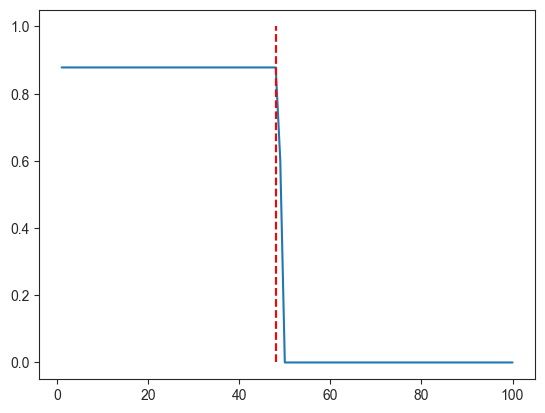

In [55]:

    # use every trial prediction instead of getting the mean probs
    probs_per_patient_resampled = []
    for i, (patient_files, patient_mean) in enumerate(zip(tot_total_trial_pred_lists, tot_mean_probs_per_patient)):
        print(i)
        print(f'New patient: files: {len(patient_files)}, {len(patient_mean)}')
        probs_patient = [] 
        print(f'patient_files: {len(patient_files[0])}')
        
        for _, timep_res_y in patient_mean:
            tot_res, tot_lab = [], []
            for file in patient_files:
                for trial in file:            
                    #print(len(trial))
                #print(len(timep_res_y))
                    tot_res += list(trial)
                    tot_lab += list(timep_res_y)
    
            #print(tot_res)
            probs_patient.append((tot_res, tot_lab))
    
        probs_per_patient_resampled.append(probs_patient)
    
    ### threshold tuning ###
    best_threshold = 0
    
    """### Threshold ###"""
    best_threshold, tot_per_tr_f1_scores = find_robust_threshold(probs_per_patient_resampled, 'f1', closest = True)
    """#################"""

    ####################################################
    ##### Final Test: robust
    ####################################################
    original_external_datasets, original_external_y = retrieve_labels(test_datasets_extracted, remove = True, flat = True)

    # one prediction per file. at the end, we would have trials (5) prediction of 13 files for any fold
    original_predictions_list, original_results_list = trials_test_CellCNN_old(models_lists, original_external_datasets)

    #Fold -> Trial -> Files' predictions
    tot_original_predictions_list.append(original_predictions_list)

    
    # define subdivision to avoid stress RAM memory 
    sub_division = sub_resampling_list(k, nsub_per_sub = 30)
        
    # Extract test labels
    test_resample_n = 100000 #same dimension of AS
    k = 2 ### 100
    seed = 42 #resampling_seeds[counter_resampling_seed]
    counter_resampling_seed += 1
    
    #test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(loaded_models_lists, per_donor_original_test_datasets, test_resample_n, k, seed, best_threshold, trials) 

    (
        test_total_labels,               # Predicted resampled subsets labels
        test_total_pred_lists,           # Mean predictions of resampled subsets across trials (per patient)
        test_total_trial_pred_lists,     # Lists of trial predictions of resampled subsets (per patient)
        per_donor_resampled_test_y       # True labels of resampled subsets (per patient)
    ) = test_res_pred(
        models_lists,
        per_donor_original_test_datasets,
        test_resample_n,
        k,
        seed,
        best_threshold,
        trials
    )
    
    predictions_for_fold.append(test_total_pred_lists)
    trials_prediction_for_fold.append(test_total_trial_pred_lists)
    resampled_y_for_fold.append(per_donor_resampled_test_y)
    
    
    save_dir = f'{cellcnn_path}/New running ipynb/Fixed/5.LOOCV_final_run/Final_model/experiment_{exp}/fold_{LOPOCV_fold_idx}/results/robust'
    os.makedirs(save_dir, exist_ok=True)
    with open(os.path.join(save_dir, 'test_total_labels.pkl'), 'wb') as f:
                    pickle.dump(test_total_labels, f)
    with open(os.path.join(save_dir, 'test_total_pred_lists.pkl'), 'wb') as f:
                    pickle.dump(test_total_pred_lists, f)
    with open(os.path.join(save_dir, 'test_total_trial_pred_lists.pkl'), 'wb') as f:
                    pickle.dump(test_total_trial_pred_lists, f)
    with open(os.path.join(save_dir, 'per_donor_resampled_test_y.pkl'), 'wb') as f:
                    pickle.dump(per_donor_resampled_test_y, f)
    with open(os.path.join(save_dir, 'per_donor_original_test_datasets.pkl'), 'wb') as f:
                    pickle.dump(per_donor_original_test_datasets, f)
    with open(os.path.join(save_dir, 'per_donor_original_test_y.pkl'), 'wb') as f:
                    pickle.dump(per_donor_original_test_y, f)

    time_per_fold.append(time.time() - fold_time_start)
    print(f' Fold time: {time_per_fold}')

    if LOPOCV_fold_idx == 0:
        break

full_process_time = time.time() - full_process_time_start
print(f'Total elapsed time: {full_process_time}')


In [33]:
TUNED_THRESHOLD = opt_threshold*100

In [34]:
#test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(models_lists, per_donor_original_test_datasets, test_resample_n, k, seed, TUNED_THRESHOLD, trials)


from sklearn.metrics import f1_score

def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []

    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"

            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets

                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)

                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)

                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })


                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)

            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })

            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })

    return prob_data, boxplot_data, f1_data


print(f'Predicted  Labels: {test_total_labels}')

print(f'Timepoints Labels: {per_donor_original_test_y}')

plot_data, boxplot_data, f1_data = final_trials_prediction(test_total_trial_pred_lists,
                                                           per_donor_original_test_y, per_donor_resampled_test_y, TUNED_THRESHOLD)

Predicted  Labels: [[1, 1, 1]]
Timepoints Labels: [[1, 1, 0]]


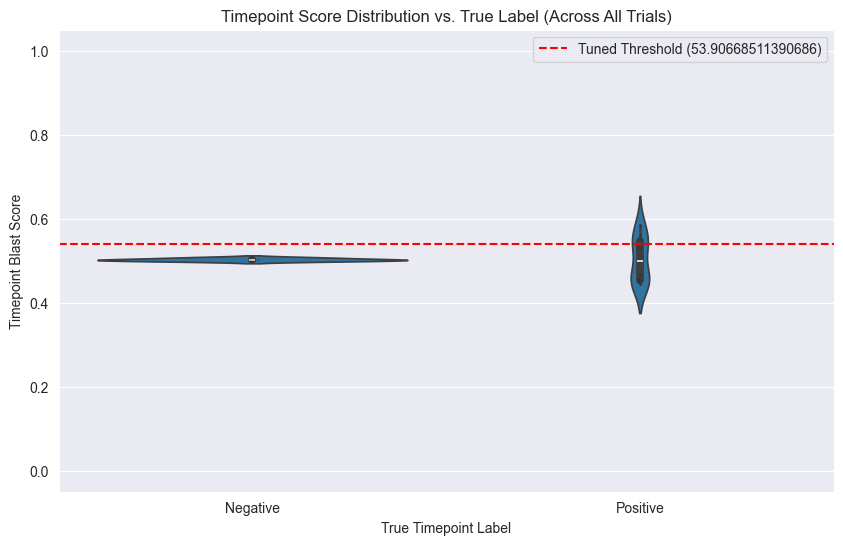

In [35]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert your data into a DataFrame
df = pd.DataFrame(plot_data)

# --- Create the plot ---
plt.figure(figsize=(10, 6))

# A Violin plot is like a boxplot but shows the full distribution
sns.violinplot(
    x="True_Label",
    y="Timepoint_Score",
    data=df,
    order=["Negative", "Positive"] # Ensure this order
)

# You can also add a swarmplot to see the individual points
sns.swarmplot(
    x="True_Label",
    y="Timepoint_Score",
    data=df,
    color="black",
    alpha=0.2, # Make points transparent
    size=2,
    order=["Negative", "Positive"]
)

# --- Add your threshold line! ---
# This is the line that separates your predictions
# The threshold you found in your tuning
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')
plt.ylim(-0.05, 1.05) # (Set the y-axis limit, 1.05 gives a little space)
plt.title('Timepoint Score Distribution vs. True Label (Across All Trials)')
plt.ylabel('Timepoint Blast Score')
plt.xlabel('True Timepoint Label')
plt.legend()
plt.show()


C:\Users\Enrico Didoli\AppData\Local\Temp\ipykernel_7148\2816273836.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)


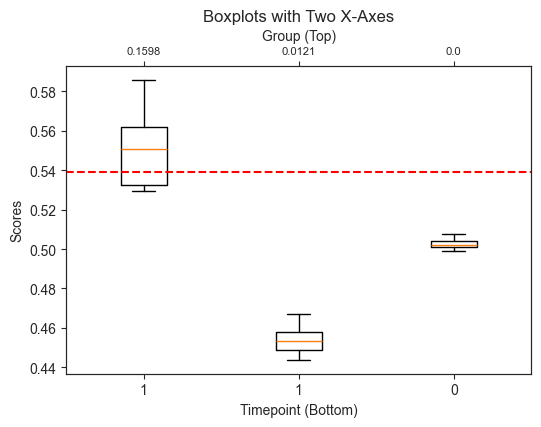

In [36]:
#print(boxplot_data)
sns.set_style("ticks")
timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
        for i, dataset in enumerate(donor):
            blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
            timepoints_blast_perc.append(round(blast_n*100,4))
            
timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(boxplot_data)]
timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in boxplot_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(6, 4))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("Scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc, fontsize=8)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

In [37]:
from sklearn.metrics import f1_score, accuracy_score, recall_score
from results_elaboration import elaborate_predictions

def elaborate_direct_prediction(imported_predictions, imported_test_y, metric = 'acc'):

    if metric == 'acc':
        pos = 0
    elif metric == 'f1':
        pos = 1
    elif metric == 'rec':
        pos = 2

    labels_flat = flatten(imported_test_y)
    # elaborate metric data from imported predictions
    models_metric_lists = []
    metrics = elaborate_metrics(imported_predictions, labels_flat)

    return metrics[pos] # extract the metric in the chosen position

def elaborate_metrics(imported_predictions, imported_test_y, results = False):
    #print(imported_predictions)
    new_pred_phenotype_df, new_accuracy_list, new_f1_score_list, new_recall_score_list = elaborate_predictions(imported_predictions, imported_test_y, results = results)
    return new_accuracy_list, new_f1_score_list, new_recall_score_list

def direct_model_comparison_barplot(direct, metric_name, subtitle = False):
    
    models_values = list(direct.values())
    models_names = [name.replace('model_', '') for name in direct.keys()]
    
    errors = []
    means = []
    for val in models_values:
        m = np.mean(val)
        means.append(m)
        s = np.std(val)
        errors.append(s)
    
    # Colors matching the plot
    colors = ['#0077BB', '#FF8800', '#00BB00', '#DD0000', '#AA55BB']
    
    # Create bar plot
    fig, ax = plt.subplots(figsize=(5, 5))
    
    bars = ax.bar(models_names, means, yerr= errors, color=colors, edgecolor='black', capsize=5)
    
    for bar, mean, error in zip(bars, means, errors):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + error,
                f'{mean:.3f}',
                ha='center', va='bottom', fontsize=10)
        
    # Customize
    plt.suptitle(f'Direct Prediction {metric_name} per method', fontsize=14, fontweight='bold')
    plt.suptitle(f'Scores (Direct Prediction)', fontsize=14, fontweight='bold')
    
    if subtitle:
        ax.set_title(f'{subtitle}', fontsize=11)
        
    ax.set_ylabel(metric_name, fontsize=12)
    high_limit = np.max(np.array(means) + np.array(errors))
    
    ax.set_ylim(0, max(1, high_limit + 0.05)) # Adjust based on your data range
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.xticks(rotation=60)
    plt.tight_layout()
    
    plt.show()


2


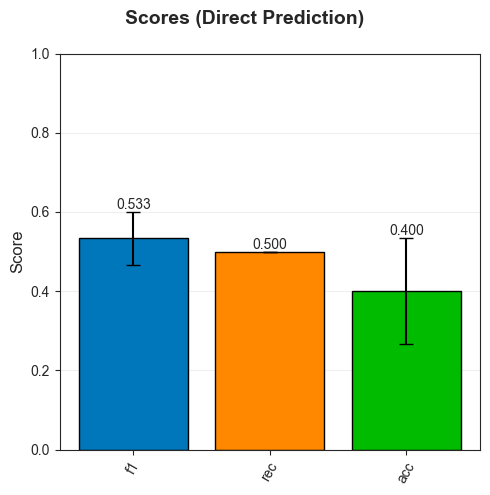

In [38]:
# mwtrics across folds

trials_mean_predictions = []
for i , trial in enumerate(original_predictions_list): 
    # trial
    trials_mean = np.mean(trial, axis = 0).tolist() # mean across trials inside the fold
    trials_mean_predictions.append(trials_mean)
print(len(trials_mean))

direct_metrics_across_trials= {}



dir_f1 = elaborate_direct_prediction(original_predictions_list, per_donor_original_test_y, 'f1')
dir_rec = elaborate_direct_prediction(original_predictions_list, per_donor_original_test_y, 'rec')
dir_acc = elaborate_direct_prediction(original_predictions_list, per_donor_original_test_y, 'acc')


mod_n = 'f1'
direct_metrics_across_trials[mod_n] = dir_f1
mod_n = 'rec'
direct_metrics_across_trials[mod_n] = dir_rec
mod_n = 'acc'
direct_metrics_across_trials[mod_n] = dir_acc

direct_model_comparison_barplot(direct_metrics_across_trials, 'Score')#, subtitle)

In [39]:
def elaborate_robust_prediction(trials_pred_lists, imported_test_y, threshold):
    # group the files in a single vector
    per_files_preds = []
    for patient in trials_pred_lists:
        per_files_preds += patient
    
    # group the files labels in a single vector
    true_labels_flat = flatten(imported_test_y)
    
    files_trial_scores = []
    for i, file in enumerate(per_files_preds):
        trial_scores = []
        for trial in file:
            trial_scores.append(np.mean(trial)) # mean positive score per trial
        files_trial_scores.append(trial_scores) # for every file, a vector of |trials| each representing a file
        
    f1_model, recall_model, acc_model = [], [], []
    
    model_pred_df = pd.DataFrame(files_trial_scores).T # transpose to work on trial-level
    #print(model_pred_df)
    for trial in model_pred_df.values:
        trial_prediction = (np.array(trial) >= threshold*0.01).astype(int) # for each trial predict labels

        
        f1 = f1_score(true_labels_flat, trial_prediction, pos_label = 1, zero_division=0) # and check f1_score
        f1_model.append(f1)

        rec = recall_score(true_labels_flat, trial_prediction, pos_label = 1, zero_division=0) # and check recall
        recall_model.append(rec)

        acc = accuracy_score(true_labels_flat, trial_prediction) # and check accuracy
        acc_model.append(acc)

    return f1_model, recall_model, acc_model #list of f1_score extracted from each trial

def robust_model_comparison_barplot(all_tested_models, metric, subtitle = False):
    if metric == 'f1':
        pos = 0
        metric_name = 'F1-score'
    elif metric == 'rec':
        pos = 1
        metric_name = 'Recall'
    elif metric == 'acc':
        pos = 2
        metric_name = 'Accuracy'
        
    models_metric = [model[pos] for model, _ in list(all_tested_models.values())]
    models_names = [name.replace('model_', '') for name in list(all_tested_models.keys())]

    final_predictions = [flatten(final_pred[0]) for _, final_pred in list(all_tested_models.values())]
    true_labels = [flatten(final_pred[1]) for _, final_pred in list(all_tested_models.values())]
    
    for labels in true_labels:
        if true_labels[0] != labels:
            print(f'Warnining: the model analyzed have been tested on different test sets.')
            print(f'Double check the models you are analysing!')
        

    final_f1_score = [f1_score(true_lab, pred, pos_label = 1, zero_division=0) for true_lab, pred in zip(true_labels, final_predictions)] # and check f1_score
    final_f1_score = [f1_score(true_lab, pred, pos_label = 1, zero_division=0) for true_lab, pred in zip(true_labels, final_predictions)] # and check f1_score
    
    # add the text above the bars
    if metric == 'f1':
        final_pred_score = [f1_score(true_lab, pred, pos_label = 1, zero_division=1) for true_lab, pred in zip(true_labels, final_predictions)] # and check f1_score
    if metric == 'rec':
        final_pred_score = [recall_score(true_lab, pred, pos_label = 1, zero_division=1) for true_lab, pred in zip(true_labels, final_predictions)] # and check f1_score
    if metric == 'acc':
        final_pred_score = [accuracy_score(true_lab, pred) for true_lab, pred in zip(true_labels, final_predictions)] # and check f1_score
         
    
    f1_errors = []
    f1_means = []
    for f1 in models_metric:
        m = np.mean(f1)
        f1_means.append(m)
        s = np.std(f1)
        f1_errors.append(s)
    
    # Colors matching the plot
    colors = ['#0077BB', '#FF8800', '#00BB00', '#DD0000', '#AA55BB']
    
    # Create bar plot
    fig, ax = plt.subplots(figsize=(5, 5))
    #bars = ax.bar(models_names, f1_means, yerr=f1_errors, color=colors, edgecolor='black', capsize=5)
    bars = ax.bar(models_names, final_pred_score, yerr=f1_errors, color=colors, edgecolor='black', capsize=5)

    for bar, mean, error, final_score in zip(bars, f1_means, f1_errors, final_pred_score):
        height = bar.get_height()
        
        ax.text(bar.get_x() + bar.get_width()/2., height + error,
                f'{final_score:.3f}',
                ha='center', va='bottom', fontsize=10)
        
    # Customize
    plt.suptitle(f'{metric_name} per model (Robust Approach)', fontsize=14, fontweight='bold')
    if subtitle:
        ax.set_title(f'{subtitle}', fontsize=11)
    
    ax.set_ylabel(metric_name, fontsize=12)

    # set the limits for a better visualization
    max_mean = np.max(np.array(f1_means) + np.array(f1_errors))
    max_preds = np.max(np.array(final_pred_score) + np.array(f1_errors))
    print(max_mean, max_preds)
    high_limit = max(max_mean, max_preds) # sum each element in f1_means to its elative in errors. than thake the max of the vector
    
    ax.set_ylim(0, max(1, high_limit + 0.05) ) # Adjust based on your data range
    ax.grid(True, alpha=0.3, axis='y')

    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.show()

    
def robust_prediction_labelling(trials_pred_lists, threshold):
    patient_timepoints_labels = []
    for patient in trials_pred_lists:
        file_labels = []
        for file in patient:
            positive_probs_mean = np.mean(file , axis=0) #column mean
            mean_timepoint_probs = np.mean(positive_probs_mean) #row mean to get the positive scores
         
            if mean_timepoint_probs >= threshold*0.01:
                file_labels.append(1)
            else:
                file_labels.append(0)
        patient_timepoints_labels.append(file_labels)
    return patient_timepoints_labels 
#print(patient_timepoints_labels)

0.7265986323710905 0.7265986323710905
0.5449489742783178 0.5449489742783178
0.6966326495188785 0.6966326495188785


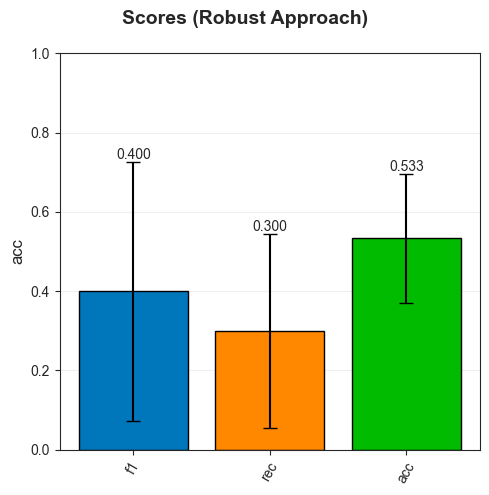

In [40]:
trials_mean_predictions = []
for trial in range(len(test_total_trial_pred_lists[0][0])):
    trial_files_mean = []
    for i, patient in enumerate(test_total_trial_pred_lists):
        for file in patient:
            #print(len(file[trial]))
            trial_files_mean.append(np.mean(file[trial]))
    #print(trial_files_mean)
            
    trials_mean_predictions.append(trial_files_mean)
    
    
    
rob_f1, rob_rec, rob_acc = [], [], []
true_labels_flat = flatten(per_donor_original_test_y)
for trial in trials_mean_predictions:
        trial_prediction = (np.array(trial) >= TUNED_THRESHOLD*0.01).astype(int) # for each trial predict labels

        
        f1 = f1_score(true_labels_flat, trial_prediction, pos_label = 1, zero_division=0) # and check f1_score
        rob_f1.append(f1)

        rec = recall_score(true_labels_flat, trial_prediction, pos_label = 1, zero_division=0) # and check recall
        rob_rec.append(rec)

        acc = accuracy_score(true_labels_flat, trial_prediction) # and check accuracy
        rob_acc.append(acc)
    
mod_n = ['f1', 'rec', 'acc']
metric_names = ['f1', 'rec', 'acc']
subtitle = None
# Create bar plot
fig, ax = plt.subplots(figsize=(5, 5))
for i, metric_name in enumerate(metric_names): 

    
    f1_errors = []
    f1_means = []
    if metric_name == 'f1':
        f1 = rob_f1
    elif metric_name == 'rec':
        f1 = rob_rec
    elif metric_name == 'acc':
        f1 = rob_acc
    
    m = np.mean(f1)
    f1_means.append(m)
    s = np.std(f1)
    f1_errors.append(s)
    
    # Colors matching the plot
    colors = ['#0077BB', '#FF8800', '#00BB00', '#DD0000', '#AA55BB']
    
    
    #bars = ax.bar(models_names, f1_means, yerr=f1_errors, color=colors, edgecolor='black', capsize=5)
    bars = ax.bar(mod_n[i],f1_means, yerr=f1_errors, color=colors[i], edgecolor='black', capsize=5)

    for bar, mean, error, final_score in zip(bars, f1_means, f1_errors, f1_means):
        height = bar.get_height()
        
        ax.text(bar.get_x() + bar.get_width()/2., height + error,
                f'{final_score:.3f}',
                ha='center', va='bottom', fontsize=10)
        
    # Customize
    #plt.suptitle(f'{metric_name} per model (Robust Approach)', fontsize=14, fontweight='bold')
    plt.suptitle(f'Scores (Robust Approach)', fontsize=14, fontweight='bold')
    
    if subtitle:
        ax.set_title(f'{subtitle}', fontsize=11)
    
    ax.set_ylabel(metric_name, fontsize=12)

    # set the limits for a better visualization
    max_mean = np.max(np.array(f1_means) + np.array(f1_errors))
    max_preds = np.max(np.array(f1_means) + np.array(f1_errors))
    print(max_mean, max_preds)
    high_limit = max(max_mean, max_preds) # sum each element in f1_means to its elative in errors. than thake the max of the vector
    
    ax.set_ylim(0, max(1, high_limit + 0.05) ) # Adjust based on your data range
    ax.grid(True, alpha=0.3, axis='y')

    plt.xticks(rotation=60)
    plt.tight_layout()
plt.show()


